In [1]:
import os
from dotenv import load_dotenv
load_dotenv()
from langchain_groq import ChatGroq
os.environ['GROQ_API_KEY'] = os.getenv('GROQ_API_KEY')
llm = ChatGroq(model="qwen/qwen3.8-27b")

In [ ]:
result = llm.invoke("WHat is groq?")
result

In [3]:
def add(a: float, b: float) -> float:
  """Add two numbers.

  Args:
    a: first number
    b: second number
  """
  return a + b

def subtract(a: float, b: float) -> float:
  """Subtract b from a.

  Args:
    a: first number
    b: number to subtract from a
  """
  return a - b

def multiply(a: float, b: float) -> float:
  """Multiply two numbers.

  Args:
    a: first number
    b: second number
  """
  return a * b

def divide(a: float, b: float) -> float | str:
  """Divide a by b.

  Args:
    a: dividend
    b: divisor
  """
  if b == 0:
    return "Error: division by zero"
  return a / b

In [5]:
tools = [add, subtract, multiply, divide]
tools

[<function __main__.add(a: float, b: float) -> float>,
 <function __main__.subtract(a: float, b: float) -> float>,
 <function __main__.multiply(a: float, b: float) -> float>,
 <function __main__.divide(a: float, b: float) -> float | str>]

In [6]:
llm_with_tools = llm.bind_tools(tools)
llm_with_tools

_ChatModelBinding(bound=ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.3', 'langchain': '1.4.7'}}, client=<groq.resources.chat.completions.Completions object at 0x10e748a40>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x10e895910>, model_name='qwen/qwen3.8-27b', model_kwargs={}, groq_api_key=SecretStr('**********')), kwargs={'tools': [{'type': 'function', 'function': {'name': 'add', 'description': 'Add two numbers.', 'parameters': {'properties': {'a': {'description': 'first number', 'type': 'number'}, 'b': {'description': 'second number', 'type': 'number'}}, 'required': ['a', 'b'], 'type': 'object'}}}, {'type': 'function', 'function': {'name': 'subtract', 'description': 'Subtract b from a.', 'parameters': {'properties': {'a': {'description': 'first number', 'type': 'number'}, 'b': {'description': 'number to subtract from a', 'type': 'number'}}, 'required': ['a', 'b'], 'type': 'object'}}}, {'type': 'function', 'function': {'name': 'multiply', 'de

In [8]:
from IPython.display import Image, display
from langgraph.checkpoint.memory import MemorySaver
from langgraph.graph import MessagesState, START, StateGraph
from langgraph.prebuilt import tools_condition, ToolNode
from langchain_core.messages import AIMessage, SystemMessage, HumanMessage

sys_msg = SystemMessage(content="You're a helpfull assistant tasked with performing arithmetic on a set of input.")

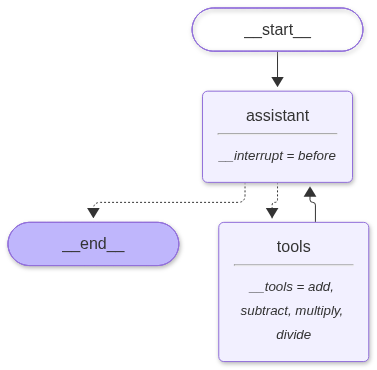

In [11]:
def assistant(state: MessagesState):
    return {"messages": [llm_with_tools.invoke([sys_msg] + state["messages"])]}

builder = StateGraph(MessagesState)
builder.add_node("assistant", assistant)
builder.add_node("tools", ToolNode(tools))
builder.add_edge(START, "assistant")

builder.add_conditional_edges(
    "assistant",
    tools_condition
)

builder.add_edge("tools", "assistant")

memory = MemorySaver()
graph = builder.compile(interrupt_before=["assistant"], checkpointer=memory)
display(Image(graph.get_graph().draw_mermaid_png()))

In [12]:
thread = {"configurable": {"thread_id": "123"}}
initial_input = {"messages": HumanMessage(content="multiply 2 & 3")}


In [13]:
for event in graph.stream(initial_input, thread, stream_mode="values"):
    event["messages"][-1].pretty_print()

================================ Human Message =================================

multiply 2 & 3


In [15]:
state = graph.get_state(thread)
state.next

('assistant',)

In [16]:
for event in graph.stream(None, thread, stream_mode="values"):
    event["messages"][-1].pretty_print()

================================ Human Message =================================

multiply 2 & 3
================================== Ai Message ==================================
Tool Calls:
  multiply (sn01gjcb3)
 Call ID: sn01gjcb3
  Args:
    a: 2
    b: 3
================================= Tool Message =================================
Name: multiply

6.0


In [17]:
for event in graph.stream(None, thread, stream_mode="values"):
    event["messages"][-1].pretty_print()

================================= Tool Message =================================
Name: multiply

6.0
================================== Ai Message ==================================

The result of multiplying 2 and 3 is **6**.
